# Import relevant libraries

In [1]:
#mamba install -c conda-forge leafmap

In [2]:
import os
import leafmap.leafmap as leafmap
import sys
import anuga
import glob
import h5netcdf
import xarray as xr
import rioxarray as rxr
import pandas as pd
import geopandas as gpd
import contextily as cx
import numpy as np
import matplotlib.pyplot as plt
import hvplot.xarray
import zipfile
import rasterio

from rasterio.enums import Resampling
from rasterio.mask import mask
import rasterio
import rasterio.plot
import fiona
import csv
from shapely.geometry import mapping
from pyproj import CRS
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from anuga.file.netcdf import NetCDFFile
from netCDF4 import Dataset
from anuga.utilities.plot_utils import Make_Geotif
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr, pearsonr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from osgeo import gdal

from pathlib import Path
import matplotlib as mpl
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import matplotlib.gridspec as gridspec
from datetime import datetime



# Import datasets

In [3]:
os.chdir('/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/MODEL_folder/test_work_folder')
work_folder = os.getcwd()
print("Current working directory:", work_folder)

Current working directory: /Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/MODEL_folder/test_work_folder


In [4]:
#Processing all SWOT cal/val
swot_dir = '/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/MODEL_folder/test_swot_folder'
water_mask_shp = "/Users/skica/Desktop/2025_Summer_Research/FINAL_PRESENTATION_FIGURES/water_mask_utm.geojson"
water_mask=gpd.read_file(water_mask_shp)

gauge_path= '/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/open_water/gauge_locations_komo.shp'
gauge_loc = gpd.read_file(gauge_path)

<Axes: >

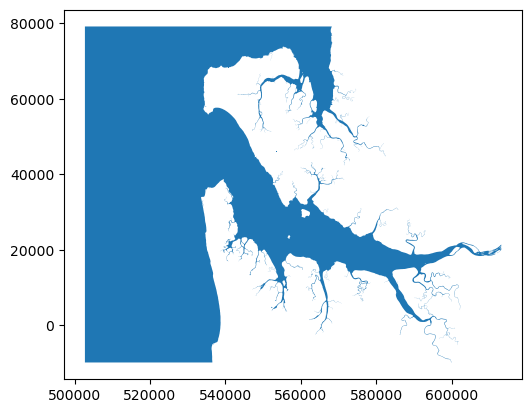

In [5]:
water_mask.plot() ### Water mask

# Load and process SWOT WSE data for comparison

In [6]:
swot_files = sorted(glob.glob(os.path.join(swot_dir, "*.nc")))

In [7]:
len(swot_files)

206

In [ ]:
#mangrove_height_path = '/Users/skica/Desktop/2025_Summer_Research/work_folder_inundation/NISAR/TDM1_DEM__04_N00E009_DEM_EGM08_GMW314_2015_WM_hcap_cal.tif'
# m = leafmap.Map(scale_control=True,draw_control=False,attribution_control=False,toolbar_control=False)
# m.add_basemap("Satellite")
# m.add_vector(water_mask_shp,info_mode='on_hover',zoom_to_layer=True, layer_name="Water mask",style={"color": "grey", "weight": 0.3})
#m.add_colormap(cmap="Blue", label=f"Water mask")

for file in swot_files:
    try:
        swotFileName = os.path.splitext(os.path.basename(file))[0]
        ds_raster = xr.open_dataset(file, engine='h5netcdf')

        
        #Begin---------------------This code block retrieves integers from the bitwise_qual flags----------------------
        quality_variables = {}
        for name, variable in ds_raster.variables.items():
            if name.endswith(("qual", "bitwise")):
                quality_variables[name] = None
        
        sorted(list(quality_variables))
        
        variable_name = "wse" #Adjust variable as needed, e.g. sig0, & wse
        quality_variable_name = f"{variable_name}_qual_bitwise"
        
        qual = ds_raster.variables[quality_variable_name].copy() 
        
        atts = dict(qual.attrs.copy())
        flags = pd.DataFrame({'flag_meanings': atts.get("flag_meanings").split(" "), 
                              'flag_masks': atts.get("flag_masks"), }) \
                  .set_index("flag_meanings")
        
        unq_ints_qual = sorted(list(set(qual.load().data.astype(np.int64).flatten().tolist())))
        
        def qual_bits_iter(n):
            while n:
                b = n & (~n+1)
                yield b
                n ^= b
        
        decomposed_qual = {}
        for i in sorted(unq_ints_qual):
            if i not in decomposed_qual:
                decomposed_qual[i] = qual_bits_iter(i)
        type(decomposed_qual), len(decomposed_qual)
        
        new_columns_qual = {}
        for i, j in enumerate(list(set(decomposed_qual))):
            new_columns_qual[j] = flags['flag_masks'] \
                .apply(lambda x: x in [b for b in qual_bits_iter(j)])
        lookup = flags.join(pd.DataFrame(new_columns_qual).sort_index(axis=1)).copy()
        
        flags_to_mask = sorted([i for i in lookup.index if i.startswith(('geo','low'))])
        #display(flags_to_mask)
        
        tmp = lookup.copy()  # Make a copy of the table.
        del tmp['flag_masks']  # Remove the 'flag_masks' column.
        indices = tmp.loc[flags_to_mask].apply(lambda x: x.any()).copy()  # Get a boolean array of integers that comprise the mask.
        integers_to_mask = sorted(tmp.columns[indices].astype(np.int64).tolist())  # Get the columns/integers with one or more flag set to True.
        #print(f"Unique integers to mask in {swotFileName}: ",len(integers_to_mask))
        #print(integers_to_mask)       
        #-End--------------------This code block retrieves integers from the bitwise_qual flags----------------------



        
        #--Begin------------This code block filters the SWOT WSE data based on the integers retrieved above-----------
        # Apply the cross_track 
        c_track_cond = ((ds_raster['cross_track'] > 10000) & (ds_raster['cross_track'] < 60000)) | \
                      ((ds_raster['cross_track'] < -10000) & (ds_raster['cross_track'] > -60000))
        # #Apply number of pixels
        n_wse_pix_cond = (ds_raster['n_wse_pix'] < 6)
        # wse_qual_bit_cond = (ds_raster['wse_qual_bitwise'] == 0)
        wse_qual_cond = (ds_raster['wse_qual'] >= 2)
        # wa_qual_bit_cond = (ds_raster['water_area_qual_bitwise']==0)
        water_frac_cond = (ds_raster['water_frac'] < 0.5) #& (ds_raster['water_frac']<1.0001)
        dark_frac_cond = (ds_raster['dark_frac']> 0.9)
        wa_q_cond = (ds_raster['wse_qual']==0)
        
        # Apply bitwise filtering
        bitwise_cond = np.isin(ds_raster[f'{variable_name}_qual_bitwise'], integers_to_mask)
        bad_pixels = bitwise_cond | water_frac_cond #| dark_frac_cond#| n_wse_pix_cond #| wse_qual_cond
        comb_cond = c_track_cond & ~bad_pixels #bitwise_cond & dark_frac_cond #wse_qual_bit_cond #& water_frac_cond # & wse_qual_cond & wa_qual_bit_cond & #& n_wse_pix_cond #& bitwise_cond ### Add the different conditions you want to mask at this point
        
        xs = ds_raster["wse"].where(comb_cond.compute())# & bitwise_cond, drop=True)
        # Manually compute bounds of remaining data
        x0, x1 = xs.x.min().item(), xs.x.max().item()
        y0, y1 = xs.y.min().item(), xs.y.max().item()
        
        xs = xs.rio.write_crs("EPSG:32632")
        xs = xs.rio.clip_box(minx=x0, miny=y0, maxx=x1, maxy=y1, crs="EPSG:32632")
        xs.rio.to_raster(f"{swotFileName}_test.tif") #test if not geometrically correct
        #--End------------This code block filters the SWOT WSE data based on the integers retrieved above-----------



        
        #--BEgin----------This code block masks the SWOT datasets to the water mask-------------------------------
        if isinstance(xs, xr.Dataset):
            xs = xs[list(xs.data_vars)[0]]  # Grab first variable
        water_mask = water_mask.to_crs(xs.rio.crs) # Reproject vector to raster CRS
        xs_clipped = xs.rio.clip(water_mask.geometry, water_mask.crs, drop=True)     # Clip using rioxarray
        xs_clipped = xs_clipped.where(xs_clipped != 0, np.nan)  # Replace 0 with NaN if needed
        xs_clipped = xs_clipped.rio.write_crs("EPSG:32632")
        xs_clipped.rio.to_raster(f'water_test_{swotFileName}.tif') # Export to GeoTIFF
        #--End----------This code block masks the SWOT datasets to the water mask---------------------------------



        
        ###-----------------------------Plotting the swot rasters------------------------------------------------
        # Choose basemap (Stamen 'terrain', 'toner', or 'watercolor' available)
                # Assumes the 13th underscore-separated part is like '20230410T092115'
        start_str = swotFileName.split("_")[13]
        dt = datetime.strptime(start_str, "%Y%m%dT%H%M%S")
        
        # mpl.rcParams["font.family"] = "Times"
        # swot_water_latlon  = xs_clipped.squeeze().rio.reproject("EPSG:4326").squeeze()
        # #proj = ccrs.PlateCarree()

        # fig, ax = plt.subplots(figsize=(6, 6))
        # da2d = swot_water_latlon.squeeze()
        # west, south, east, north = da2d.rio.bounds()
            
        # swot_water_latlon.plot(ax=ax, cmap="viridis", cbar_kwargs={"label": "Water Surface Elevation (m)"})
        # ax.set_title(dt)
        ###-----------------------------Plotting the swot rasters------------------------------------------------
        print(f"Processing {swotFileName} ...")

        
        #----------------Plotting on webmap----------
        filename = leafmap.array_to_image(xs_clipped) #waterFile
        m.add_raster(filename, colormap="viridis", layer_name=start_str,legend_title=start_str, nodata=np.nan,vmin=-1.4,vmax=1.40)
        
        #----------------Plotting on webmap----------

        
        ds_raster.close()

    except Exception as e:
        print(f"Error processing {swotFileName}: {e}")
#--------------Uncomment for visuals------------------------------
# m.add_vector(gauge_path,info_mode='on_hover',zoom_to_layer=True, layer_name="Gauges")
# m.add_colormap(cmap="viridis", label=f"Water Surface Elevation (m)",vmin=-0.5,vmax=1.50)
# m.add("inspector")
# m.add_layer_manager()
# display(m)


Error processing SWOT_L2_HR_Raster_100m_UTM32M_N_x_x_x_482_016_078F_20230406T095902_20230406T095923_PGC0_01: No data found in bounds. Data variable: wse
Error processing SWOT_L2_HR_Raster_100m_UTM32M_N_x_x_x_483_016_078F_20230407T094941_20230407T095002_PGC0_01: No data found in bounds. Data variable: wse
Error processing SWOT_L2_HR_Raster_100m_UTM32M_N_x_x_x_484_016_078F_20230408T094019_20230408T094040_PGC0_01: No data found in bounds. Data variable: wse
Error processing SWOT_L2_HR_Raster_100m_UTM32M_N_x_x_x_485_016_078F_20230409T093057_20230409T093118_PGC0_01: No data found in bounds. Data variable: wse
Error processing SWOT_L2_HR_Raster_100m_UTM32M_N_x_x_x_486_016_078F_20230410T092135_20230410T092156_PGC0_01: No data found in bounds. Data variable: wse
Error processing SWOT_L2_HR_Raster_100m_UTM32M_N_x_x_x_487_016_078F_20230411T091213_20230411T091234_PGC0_01: No data found in bounds. Data variable: wse
Error processing SWOT_L2_HR_Raster_100m_UTM32M_N_x_x_x_487_016_078F_20230411T09121

# Validating SWOT WSE data

### Create buffer

In [26]:
#gdf = gpd.read_file("/Users/solomonkica/Desktop/test/gaugeLocations.shp")
buffer_distance = 1000 # meters
gauge_loc["geometry"] = gauge_loc.buffer(buffer_distance)

buff_file = "/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/open_water/gaugeLocations_trial.geojson" 
gauge_loc.to_file(buff_file, driver="GeoJSON") 
print(f"GeoDataFrame has been written to {buff_file}")

GeoDataFrame has been written to /Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/open_water/gaugeLocations_trial.geojson


### Masking SWOT wse's to buffers

In [27]:
raster_folder = '/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/open_water'
for raster_file in [f for f in os.listdir(raster_folder) 
                   if f.startswith('water_test_SWOT') and f.endswith('.tif')]:
    raster_path = os.path.join(raster_folder, raster_file)
    
    src = rasterio.open(raster_path)
    data = src.read()

    with fiona.open(buff_file, "r") as f:
        shapes = [feature["geometry"] for feature in f]
    out_image, out_transform = rasterio.mask.mask(src, shapes, crop=True,nodata=np.nan)

    out_meta = src.meta 
    out_meta.update( 
        {
            "driver": "GTiff", 
            "height": out_image.shape[1], 
            "width": out_image.shape[2], 
            "transform": out_transform,
            "nodata":np.nan
        }
     )
    out_path = os.path.join(raster_folder, f"masked_{raster_file}")
    with rasterio.open(out_path, "w", **out_meta) as dst: 
        dst.write(out_image)

### Create csv to hold SWOT wse statistics at gauge

In [28]:
# Prepare CSV output
csv_header = ['RasterFile', 'StationID', 'MEAN', 'MEDIAN', 'MIN', 'MAX', 
              'RANGE', 'STD', 'SUM', 'COUNT', 'PCT90']

output_csv="/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/open_water/csv_SWOT_WSE_stats_allCalVal2.csv"
with open(output_csv, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(csv_header)

### Processing raster statistics

In [29]:
# Process each raster file

for raster_file in [f for f in os.listdir(raster_folder) 
                   if f.startswith('masked_') and f.endswith('.tif')]:
    raster_path = os.path.join(raster_folder, raster_file)
    with rasterio.open(raster_path) as src:
        nodata_val = src.nodata if src.nodata is not None else -9999  # Adjust if needed

        for idx, station in gauge_loc.iterrows():
            geom = [mapping(station.geometry)]
            out_image, out_transform = mask(src, geom, crop=True)  # no masked=True

            data = out_image[0]  # first band

            # Flatten the data and filter out nodata and nan
            data_flat = data.flatten()
            valid_data = data_flat[(data_flat != nodata_val) & (~np.isnan(data_flat))]

            if len(valid_data) == 0:
                #print(f"Station {station['station']}: No valid data") #field_name in gauge data: 'station'
                continue

            stats = {
                'MEAN': np.mean(valid_data),
                'MEDIAN': np.median(valid_data),
                'MIN': np.min(valid_data),
                'MAX': np.max(valid_data),
                'RANGE': np.ptp(valid_data),
                'STD': np.std(valid_data),
                'SUM': np.sum(valid_data),
                'COUNT': len(valid_data),
                'PCT90': np.percentile(valid_data, 90)
            }

            with open(output_csv, 'a', newline='') as f:
                writer = csv.writer(f)
                writer.writerow([
                    raster_file,
                    station['station'],
                    *[stats[k] for k in csv_header[2:]]
                ])